### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import textwrap

import warnings
warnings.filterwarnings("ignore")

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [75]:
data = pd.read_csv('data/coupons.csv')

In [76]:
pd.set_option('display.max_columns', None)
data.head()


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,car,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,NaN,never,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [77]:
#data.isnull().sum()
data.describe()
data.dtypes

destination             object
passanger               object
weather                 object
temperature              int64
time                    object
coupon                  object
expiration              object
gender                  object
age                     object
maritalStatus           object
has_children             int64
education               object
occupation              object
income                  object
car                     object
Bar                     object
CoffeeHouse             object
CarryAway               object
RestaurantLessThan20    object
Restaurant20To50        object
toCoupon_GEQ5min         int64
toCoupon_GEQ15min        int64
toCoupon_GEQ25min        int64
direction_same           int64
direction_opp            int64
Y                        int64
dtype: object

In [78]:
data['Bar'].unique()


array(['never', 'less1', '1~3', 'gt8', nan, '4~8'], dtype=object)

3. Decide what to do about your missing data -- drop, replace, other...

In [79]:
#find the columns with missing data as % of total rows
missing_data = data.isnull().sum() / len(data) * 100
print(missing_data)

destination              0.000000
passanger                0.000000
weather                  0.000000
temperature              0.000000
time                     0.000000
coupon                   0.000000
expiration               0.000000
gender                   0.000000
age                      0.000000
maritalStatus            0.000000
has_children             0.000000
education                0.000000
occupation               0.000000
income                   0.000000
car                     99.148534
Bar                      0.843582
CoffeeHouse              1.710817
CarryAway                1.190476
RestaurantLessThan20     1.024913
Restaurant20To50         1.490066
toCoupon_GEQ5min         0.000000
toCoupon_GEQ15min        0.000000
toCoupon_GEQ25min        0.000000
direction_same           0.000000
direction_opp            0.000000
Y                        0.000000
dtype: float64


In [80]:
# given the high missing data for car column, we can drop it
data_clean = data.drop(columns=['car'])

# for bar , coffeehouse, carryaway, restaurantlessthan20, restaurant20to50 we can impute the missing values with the mode

columns_to_impute = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']

for col in columns_to_impute:
    mode_value = data_clean[col].mode()[0]
    data_clean[col].fillna(mode_value, inplace=True)


In [81]:
data_clean.sample(5)

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
246,No Urgent Place,Friend(s),Sunny,80,6PM,Restaurant(<20),2h,Female,21,Single,0,High School Graduate,Unemployed,Less than $12500,1~3,never,4~8,1~3,less1,1,1,0,0,1,1
5030,No Urgent Place,Friend(s),Sunny,80,6PM,Restaurant(<20),1d,Male,21,Single,0,Bachelors degree,Computer & Mathematical,$12500 - $24999,less1,1~3,gt8,gt8,1~3,1,1,0,0,1,1
12144,Home,Alone,Sunny,80,6PM,Restaurant(20-50),1d,Female,21,Unmarried partner,0,Bachelors degree,Unemployed,$25000 - $37499,never,never,1~3,1~3,less1,1,0,0,1,0,0
9747,Work,Alone,Sunny,80,7AM,Coffee House,1d,Male,26,Single,0,Some college - no degree,Unemployed,$87500 - $99999,never,1~3,4~8,less1,never,1,0,0,1,0,1
7495,Home,Alone,Snowy,30,6PM,Coffee House,1d,Male,26,Single,0,Bachelors degree,Unemployed,$62500 - $74999,4~8,never,4~8,1~3,less1,1,1,0,0,1,0


4. What proportion of the total observations chose to accept the coupon?



Percentage of 'Yes' responses: 56.84%
Percentage of 'No' responses: 43.16%


<Axes: xlabel='Y', ylabel='count'>

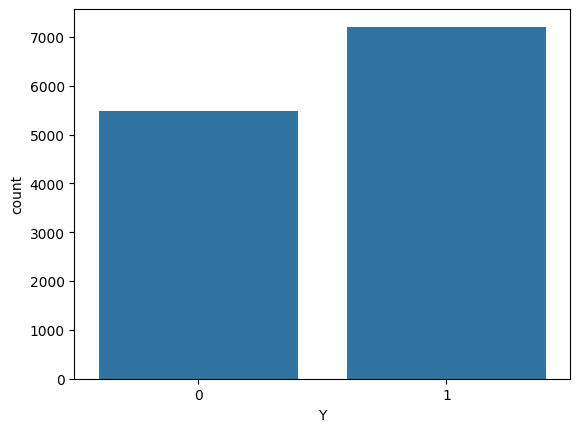

In [115]:
#find the distribution of the target variable 'Y'
percent_yes = data_clean['Y'].mean() * 100
percent_no = 100 - percent_yes
print(f"Percentage of 'Yes' responses: {percent_yes:.2f}%")
print(f"Percentage of 'No' responses: {percent_no:.2f}%")
sns.countplot(x='Y', data=data_clean)

5. Use a bar plot to visualize the `coupon` column.

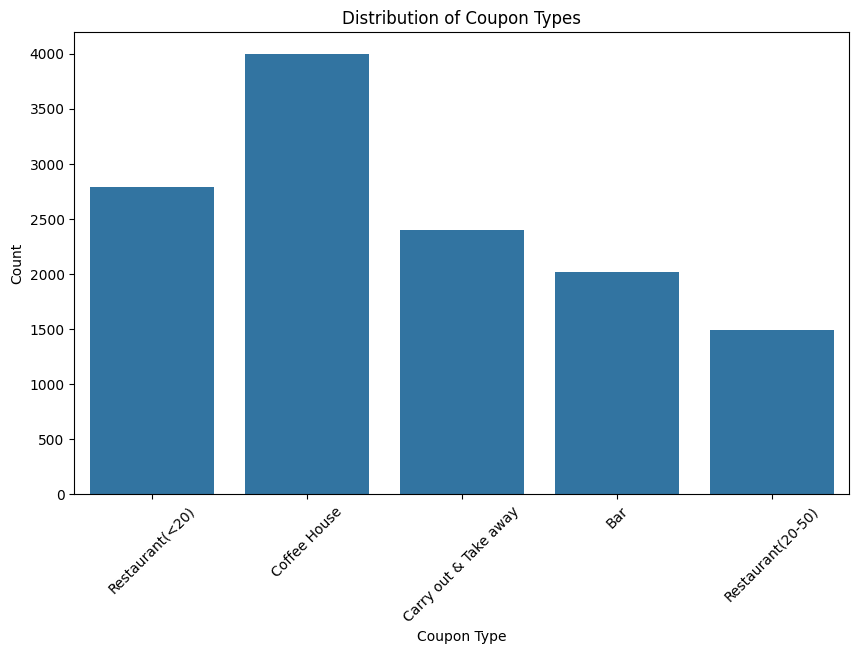

In [83]:
#visualiziing the coupon column 
plt.figure(figsize=(10, 6))
sns.countplot(x='coupon', data=data_clean)
plt.title('Distribution of Coupon Types')
plt.xlabel('Coupon Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()


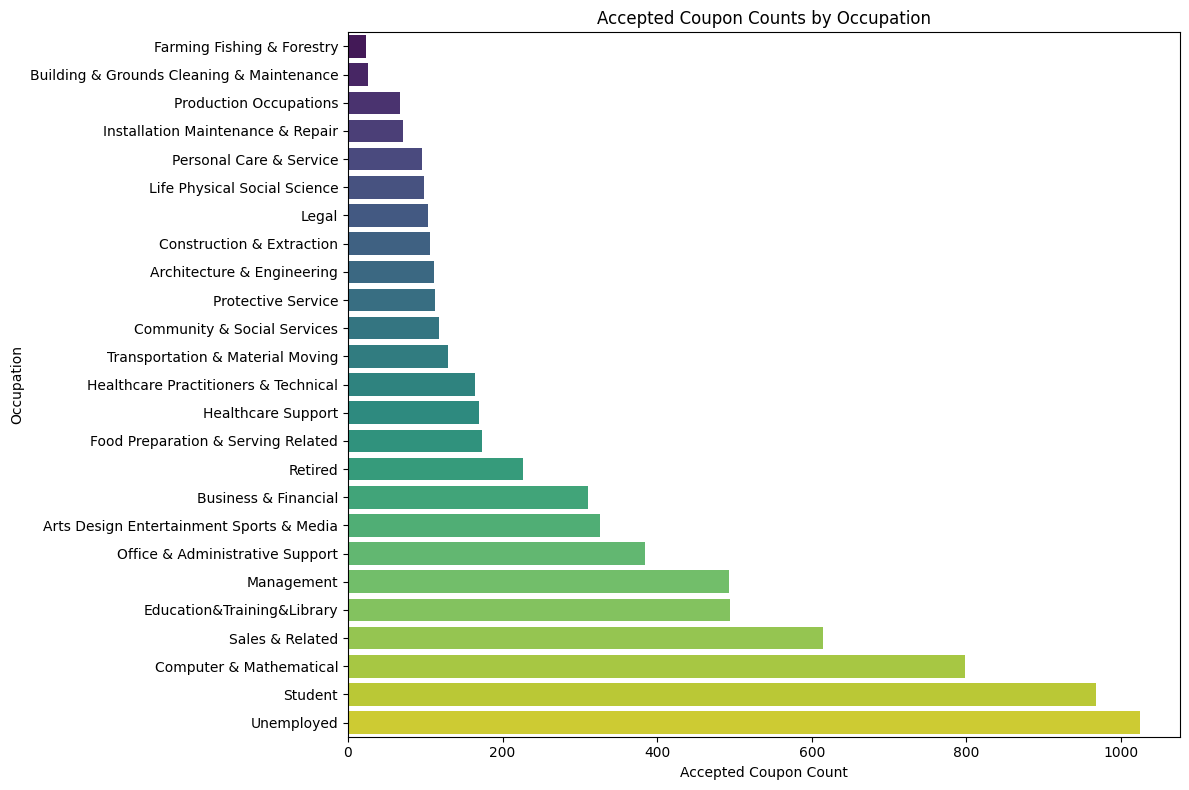

In [84]:
#plotting the distribution of accepted coupons by occupation
accepted_by_occupation = data_clean[data_clean['Y'] == 1]['occupation'].value_counts().sort_values()

plt.figure(figsize=(12, 8))
sns.barplot(x=accepted_by_occupation.values, y=accepted_by_occupation.index, palette='viridis')
plt.title('Accepted Coupon Counts by Occupation')
plt.xlabel('Accepted Coupon Count')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

In [85]:

result = len(data_clean['temperature'].unique())
print(f"Number of unique temperature values: {result}")



Number of unique temperature values: 3


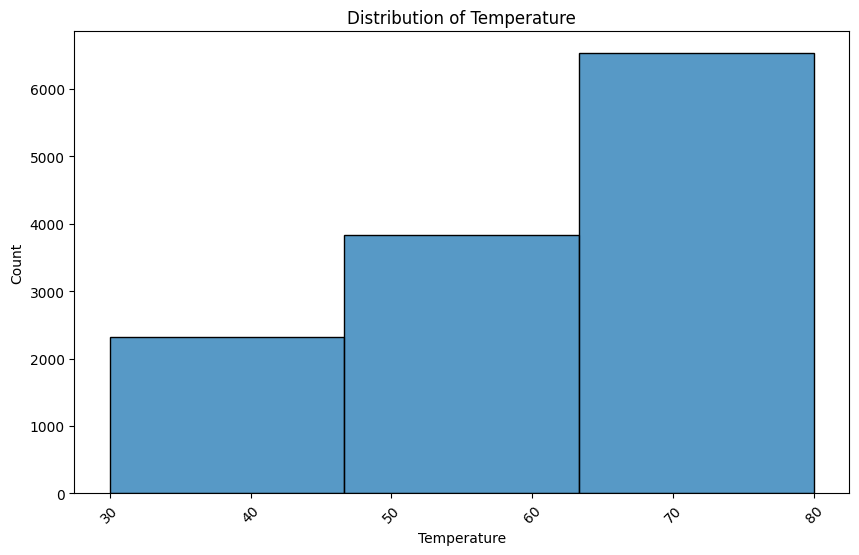

In [86]:
plt.figure(figsize=(10, 6))
sns.histplot(x='temperature', data=data_clean, bins=result)
plt.title('Distribution of Temperature')
plt.xlabel('Temperature')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [87]:
#putting all rows from the  column 'coupon' with 'Bar' into a new dataframe
data_bar = data_clean[data_clean['coupon'].str.contains('Bar', regex=False, na=False)].copy()
data_bar.head() 


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,0,Bachelors degree,Architecture & Engineering,$62500 - $74999,never,less1,4~8,4~8,less1,1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [88]:
# the % of coupons with 'Bar' that were accepted (Y=1)
percent_bar_accepted = data_bar['Y'].mean() * 100
print(f"Percentage of 'Bar' coupons accepted: {percent_bar_accepted:.2f}%")

Percentage of 'Bar' coupons accepted: 41.00%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [89]:
data_bar['Bar'].unique()

array(['never', 'less1', '1~3', 'gt8', '4~8'], dtype=object)

In [90]:
#creating 2 bins based on the above criteria
low_freq = data_bar[data_bar['Bar'].isin(['never', 'less1', '1~3'])]
high_freq = data_bar[data_bar['Bar'].isin(['4~8', 'gt8'])]
# the % of coupons with 'Bar' that were accepted (Y=1) for low frequency users
percent_low_freq_accepted = low_freq['Y'].mean() * 100
print(f"Percentage of 'Bar' coupons accepted by low frequency users: {percent_low_freq_accepted:.2f}%")
# the % of coupons with 'Bar' that were accepted (Y=1) for high frequency users
percent_high_freq_accepted = high_freq['Y'].mean() * 100
print(f"Percentage of 'Bar' coupons accepted by high frequency users: {percent_high_freq_accepted:.2f}%")

Percentage of 'Bar' coupons accepted by low frequency users: 37.07%
Percentage of 'Bar' coupons accepted by high frequency users: 76.88%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [91]:
data_bar['age'].unique()

array(['21', '46', '26', '31', '41', '50plus', '36', 'below21'],
      dtype=object)

In [92]:
# comparing the acceptance rate for drivers going to bar more thatn once that a of age 25 to all other drivers
age_numeric = data_bar['age'].str.extract(r'(\d+)').astype(float)[0]
data_bar['age_group'] = np.where(age_numeric > 25, 'over_25', '25_and_under')
data_bar['frequency_group'] = np.where(data_bar['Bar'].isin(['1~3','4~8', 'gt8']), 'frequent', 'not frequent')
#need to put this data into a table to compare the acceptance rates for the 4 groups
grouped = data_bar.groupby(['age_group', 'frequency_group'])['Y'].mean().reset_index()
df_age_bar = pd.DataFrame(grouped)
print(df_age_bar)


      age_group frequency_group         Y
0  25_and_under        frequent  0.670455
1  25_and_under    not frequent  0.393293
2       over_25        frequent  0.695238
3       over_25    not frequent  0.263495


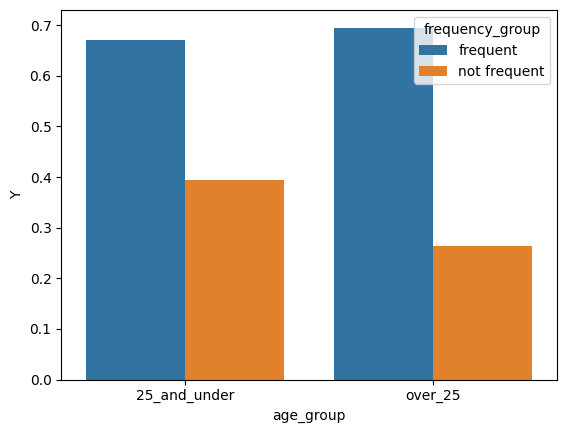

In [105]:
#plot the acceptance rates for the 4 groups

plot = sns.barplot(x='age_group', y='Y', hue='frequency_group', data=df_age_bar)

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [93]:
#drivers who go to bar more than once a month 

data_frequent_bar = data_bar[data_bar['Bar'].isin(['1~3','4~8', 'gt8'])]
pass_not_kid = data_frequent_bar[data_frequent_bar['passanger'] != 'Kid(s)']
occupation = pass_not_kid[~pass_not_kid['occupation'].str.contains('Farming|Fishing|Forestry', case=False, na=False)]

target_group = occupation[occupation['Bar'].isin(['1~3', '4~8', 'greater than 8'])]

pass_kid_grouping = target_group.groupby(['age_group', 'frequency_group'])['Y'].mean().reset_index()
pass_kid_bar = pd.DataFrame(pass_kid_grouping)
#print(pass_kid_bar)


# Filter for DRIVERS who go to bars 1 time or less a month for the comparison group
#comparison_group = passengers_no_kids[~passengers_no_kids['occupation'].str.contains('Farming|Fishing|Forestry', case=False, na=False)]
comparison_group = occupation[occupation['Bar'].isin(['never', 'less than 1'])]

target_acceptance_rate = target_group['Y'].mean() * 100
comparison_acceptance_rate = comparison_group['Y'].mean() * 100

print(f"Acceptance rate for frequent bar-goers: {target_acceptance_rate:.2f}%")
print(f"Acceptance rate for infrequent bar-goers: {comparison_acceptance_rate:.2f}%")

Acceptance rate for frequent bar-goers: 71.17%
Acceptance rate for infrequent bar-goers: nan%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [94]:
# Compare acceptance rates for the three groups described

#  Bar coupons, bars > once a month, passenger not a kid, not widowed
frequent_bar = data_bar[data_bar['Bar'].isin(['1~3', '4~8', 'gt8'])]
group1 = frequent_bar[
    (frequent_bar['passanger'] != 'Kid(s)') &
    (frequent_bar['maritalStatus'] != 'Widowed')
]

# Bar coupons, bars > once a month, age under 30
age_numeric = frequent_bar['age'].astype(str).str.extract(r'(\d+)').astype(float)[0]
group2 = frequent_bar[age_numeric < 30]

#  Bar coupons, cheap restaurants > 4 times a month, income < 50K
income_numeric = frequent_bar['income'].astype(str).str.extract(r'(\d+)').astype(float)[0]
#print (income_numeric.unique())
group3 = frequent_bar[
    frequent_bar['RestaurantLessThan20'].isin(['4~8', 'gt8']) &
    (income_numeric < 50000)
]

comparison = pd.DataFrame({
    'group': [
        'go to bars more than once a month, had passengers that were not a kid, and were not widowed',
        'go to bars more than once a month and are under the age of 30',
        'go to cheap restaurants more than 4 times a month and income is less than 50K'
    ],
    'count': [len(group1), len(group2), len(group3)],
    'acceptance_rate_%': [
        group1['Y'].mean() * 100 if len(group1) else np.nan,
        group2['Y'].mean() * 100 if len(group2) else np.nan,
        group3['Y'].mean() * 100 if len(group3) else np.nan
    ]
})

print(comparison)

                                               group  count  acceptance_rate_%
0  go to bars more than once a month, had passeng...    551          71.324864
1  go to bars more than once a month and are unde...    345          72.173913
2  go to cheap restaurants more than 4 times a mo...    130          76.923077


Text(0.5, 0, 'Group Description')

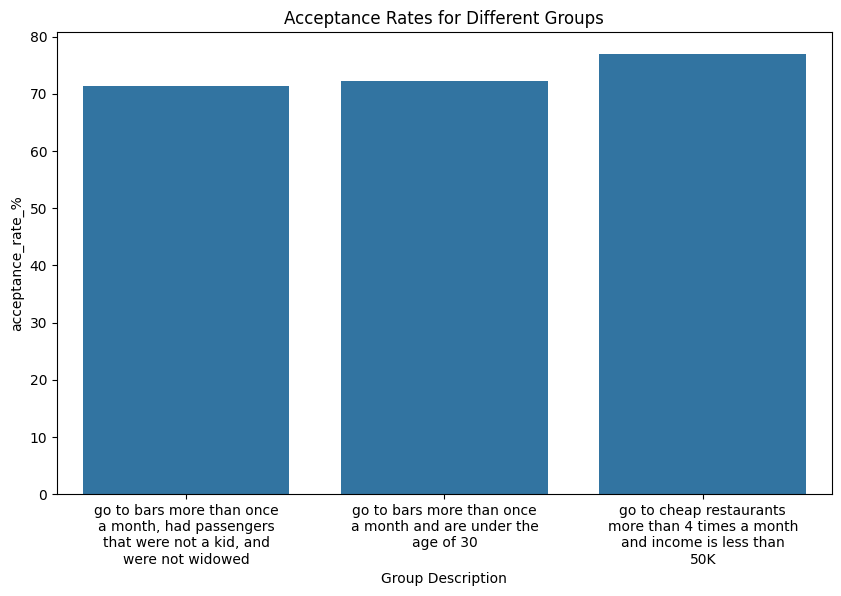

In [113]:
#plot the acceptance rates for the 3 groups
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='group', y='acceptance_rate_%', data=comparison)
plt.title('Acceptance Rates for Different Groups')
wrapped_labels = [textwrap.fill(label.get_text(), width=25) for label in ax.get_xticklabels()]
ax.set_xticklabels(wrapped_labels)
plt.xlabel('Group Description')



7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Drivers who accepted the bar coupons are likely:

* regular bar-goers (go to bars more than once a month)
* more often under 30 years old
* more likely to be riding with non-kid passengers and not widowed
* possibly more price-sensitive / lower income, since they also use cheap restaurants frequently

So the hypothesis is: accepted bar coupon drivers are generally younger, frequent bar customers, and may have lower income or value inexpensive entertainment options.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

##### I'm using the Coffee House coupon as refernce group and have analyzed teh characteristice of passengers how accept the same. Also i've checked on specifically the poplulation type that is Student and Unemployed 

In [95]:
# checking for coupon types that are not bar coupons
non_bar_coupons = data_clean[~data_clean['coupon'].str.contains('Bar', regex=False, na=False)]
print (non_bar_coupons['coupon'].unique())

['Restaurant(<20)' 'Coffee House' 'Carry out & Take away'
 'Restaurant(20-50)']


In [96]:
data_clean['CoffeeHouse'].unique()

array(['never', 'less1', '4~8', '1~3', 'gt8'], dtype=object)

In [97]:
non_bar_coupons.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,0


In [98]:
#putting all rows from the  column 'coupon' with 'CoffeeHouse' into a new dataframe
data_ch = non_bar_coupons[non_bar_coupons['coupon'].str.contains('Coffee House', regex=False, na=False)].copy()
data_ch.head() 


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,has_children,education,occupation,income,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,0,0,0,1,0
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,0
12,No Urgent Place,Kid(s),Sunny,55,6PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,1,0,0,1,1
15,Home,Alone,Sunny,80,6PM,Coffee House,2h,Female,21,Unmarried partner,1,Some college - no degree,Unemployed,$37500 - $49999,never,never,1~3,4~8,1~3,1,0,0,0,1,0


In [99]:
# the % of coupons with 'Bar' that were accepted (Y=1)
percent_ch_accepted = data_ch['Y'].mean() * 100
print(f"Percentage of 'Coffee House' coupons accepted: {percent_ch_accepted:.2f}%")

Percentage of 'Coffee House' coupons accepted: 49.92%


In [100]:
#creating 2 bins based on the above criteria
low_freq_ch = data_ch[data_ch['CoffeeHouse'].isin(['never', 'less1', '1~3'])]
high_freq_ch = data_ch[data_ch['CoffeeHouse'].isin(['4~8', 'gt8'])]
# the % of coupons with 'Coffee House' that were accepted (Y=1) for low frequency users
percent_low_freq_accepted_ch = low_freq_ch['Y'].mean() * 100
print(f"Percentage of 'Coffee House' coupons accepted by low frequency users: {percent_low_freq_accepted_ch:.2f}%")
# the % of coupons with 'Coffee House' that were accepted (Y=1) for high frequency users
percent_high_freq_accepted_ch = high_freq_ch['Y'].mean() * 100
print(f"Percentage of 'Coffee House' coupons accepted by high frequency users: {percent_high_freq_accepted_ch:.2f}%")

Percentage of 'Coffee House' coupons accepted by low frequency users: 44.96%
Percentage of 'Coffee House' coupons accepted by high frequency users: 67.50%


In [101]:
data_ch['age'].unique()

array(['21', '46', '26', '31', '41', '50plus', '36', 'below21'],
      dtype=object)

In [102]:
# comparing the acceptance rate for drivers going to Coffee house more than once that a of age 25 to all other drivers
age_numeric_ch = data_ch['age'].str.extract(r'(\d+)').astype(float)[0]
data_ch['age_group'] = np.where(age_numeric_ch > 25, 'over_25', '25_and_under')
data_ch['frequency_group'] = np.where(data_ch['CoffeeHouse'].isin(['1~3','4~8', 'gt8']), 'frequent', 'not frequent')
#need to put this data into a table to compare the acceptance rates for the 4 groups
grouped = data_ch.groupby(['age_group', 'frequency_group'])['Y'].mean().reset_index()
df_age_ch = pd.DataFrame(grouped)
print(df_age_ch)


      age_group frequency_group         Y
0  25_and_under        frequent  0.712766
1  25_and_under    not frequent  0.356540
2       over_25        frequent  0.638439
3       over_25    not frequent  0.348125


In [103]:
#drivers who go to coffee house more than once a month and are either unemployed or students occupation type

data_frequent_ch = data_ch[data_ch['CoffeeHouse'].isin(['1~3','4~8', 'gt8'])]
#pass_not_kid_ch = data_frequent_ch[data_frequent_ch['passanger'] != 'Kid(s)']
occupation_ch = data_frequent_ch[data_frequent_ch['occupation'].str.contains(r'Student|Unemployed', case=False, na=False)]

target_group_ch = occupation_ch[occupation_ch['CoffeeHouse'].isin(['1~3', '4~8', 'greater than 8'])]

# Filter for DRIVERS who go to bars 1 time or less a month for the comparison group
comparison_group_ch = occupation_ch[occupation_ch['CoffeeHouse'].isin(['never', 'less than 1'])]

target_acceptance_rate_ch = target_group_ch['Y'].mean() * 100
comparison_acceptance_rate_ch = comparison_group_ch['Y'].mean() * 100

print(f"Acceptance rate for frequent coffee house-goers who are students or unemployed: {target_acceptance_rate_ch:.2f}%")
print(f"Acceptance rate for infrequent coffee house-goers who are students or unemployed: {comparison_acceptance_rate_ch:.2f}%")

Acceptance rate for frequent coffee house-goers who are students or unemployed: 72.89%
Acceptance rate for infrequent coffee house-goers who are students or unemployed: nan%
